# Program 32: Bivariate Analysis & House Price Estimation via Linear Regression

**Scenario / Problem Statement**

Estimate house prices from house size in square feet and display the relationship and regression line.

Run the cells from top to bottom in Google Colab.

## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error


## 2. Load data and perform the analysis

Dataset loaded: FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q32_RealEstate_Bivariate.csv
Dataset shape: (60, 5)
Model Intercept: 39408.04
Model Coefficient: 164.56
R2 Score: 0.9906
RMSE: 14,298.51


,Property_ID,House_Size_SqFt,Bedrooms,Location,House_Price_USD
0,PROP-001,"1,349",2,Downtown,"$230,600"
1,PROP-002,"3,263",5,Waterfront,"$566,600"
2,PROP-003,"1,999",3,Downtown,"$351,200"
3,PROP-004,"2,030",3,Downtown,"$374,100"
4,PROP-005,"2,323",3,Waterfront,"$426,700"


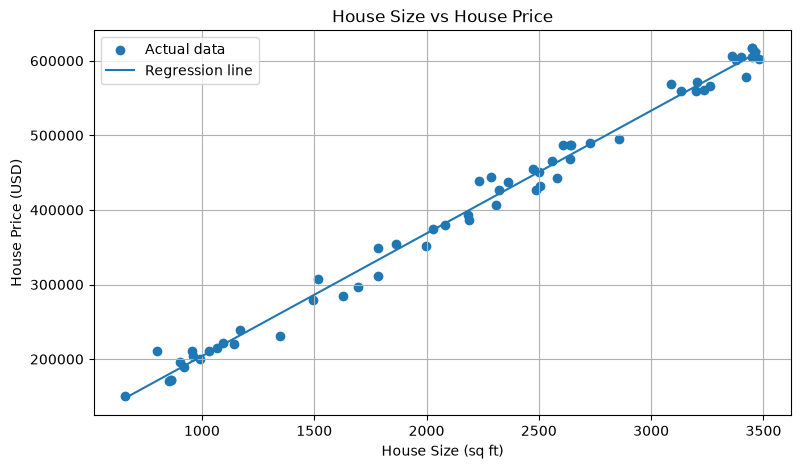

In [2]:
# Load the supplied CSV. In Colab, upload it if it is not already present.
from pathlib import Path
DATA_FILE = 'FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q32_RealEstate_Bivariate.csv'
if not Path(DATA_FILE).exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError('FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q32_RealEstate_Bivariate.csv is missing; place the CSV beside this notebook.') from exc
df_raw = pd.read_csv(DATA_FILE, skiprows=3)
print("Dataset loaded:", DATA_FILE)
print("Dataset shape:", df_raw.shape)
display(df_raw.head())

df_raw["House_Size_SqFt"] = pd.to_numeric(df_raw["House_Size_SqFt"].astype(str).str.replace(",", "", regex=False), errors="coerce")
df_raw["House_Price_USD"] = pd.to_numeric(df_raw["House_Price_USD"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False), errors="coerce")
data = df_raw.dropna(subset=["House_Size_SqFt", "House_Price_USD"])
X = data[["House_Size_SqFt"]]
y = data["House_Price_USD"]

lr = LinearRegression()
lr.fit(X, y)
preds = lr.predict(X)
print(f"Model Intercept: {lr.intercept_:.2f}")
print(f"Model Coefficient: {lr.coef_[0]:.2f}")
print(f"R2 Score: {r2_score(y, preds):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y, preds)):,.2f}")

plt.figure(figsize=(9, 5))
plt.scatter(X["House_Size_SqFt"], y, label="Actual data")
order = np.argsort(X["House_Size_SqFt"].values)
plt.plot(X["House_Size_SqFt"].values[order], preds[order], label="Regression line")
plt.title("House Size vs House Price")
plt.xlabel("House Size (sq ft)")
plt.ylabel("House Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

## 3. Result

The output above displays the required analysis, model results, or visualization.